# Does Weekly Study Time Relate to Final Grades? A Statistical Analysis of the UCI Student Performance Data

**Project 2: Data and Statistical Reasoning**

**Analytical question:** Do secondary-school students who report more weekly study time earn higher final grades in Portuguese language?

**Dataset:** Student Performance (Portuguese course, `student-por.csv`), Cortez (2008), UCI Machine Learning Repository: https://archive.ics.uci.edu/dataset/320/student+performance (DOI: https://doi.org/10.24432/C5TG7T)

**Notebook structure**
1. Setup
2. Data Loading
3. Initial Data Screening
4. Descriptive Statistics
5. Visual Models
6. Hypothesis Test
7. Notebook Summary

Author-year citations in the Markdown notes (Lusa et al., 2024; Delacre et al., 2019; Lakens, 2013; Weissgerber et al., 2015) are listed in full in the References section of `module_summary.pdf`.

## 1. Setup

In [26]:
# Core libraries for data handling, statistics, and plotting
from pathlib import Path

import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy
import seaborn as sns
from scipy import stats

# Print versions so the run can be matched against requirements.txt
for lib in (np, pd, matplotlib, sns, scipy):
    print(f"{lib.__name__:<11}{lib.__version__}")

# Consistent plot style; figures are also saved for the written report
sns.set_theme(style="whitegrid", context="notebook")
FIG_DIR = Path("figures")
FIG_DIR.mkdir(exist_ok=True)

DATA_FILE = Path("student-por.csv")
ALPHA = 0.05  # significance level, fixed before running the test

# Readable labels for the ordinal study-time codes (from the UCI data dictionary)
STUDY_LABELS = {1: "<2 h", 2: "2-5 h", 3: "5-10 h", 4: ">10 h"}

numpy      2.5.5
pandas     3.1.1
matplotlib 3.11.2
seaborn    0.13.2
scipy      1.18.1


## 2. Data Loading

The UCI file is a CSV that uses semicolons as the delimiter, so `sep=";"` is required. A small loader function keeps this step in one documented place.

In [27]:
def load_student_data(path: Path) -> pd.DataFrame:
    """Load the UCI Student Performance (Portuguese) CSV.

    The file is semicolon-delimited. Text columns are converted to the
    pandas 'category' dtype because each holds a small, fixed set of labels.
    Numeric columns (including ordinal 1-5 codes) are kept as integers.
    """
    data = pd.read_csv(path, sep=";")
    text_cols = data.select_dtypes(include=["object", "string"]).columns
    data[text_cols] = data[text_cols].astype("category")
    return data


df = load_student_data(DATA_FILE)
print(f"Rows: {df.shape[0]}, Columns: {df.shape[1]}")
df.head()

Rows: 649, Columns: 33


,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,...,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,...,4,3,4,1,1,3,4,0,11,11
1,GP,F,17,U,GT3,T,1,1,at_home,other,...,5,3,3,1,1,3,2,9,11,11
2,GP,F,15,U,LE3,T,1,1,at_home,other,...,4,3,2,2,3,3,6,12,13,12
3,GP,F,15,U,GT3,T,4,2,health,services,...,3,2,2,1,1,5,0,14,14,14
4,GP,F,16,U,GT3,T,3,3,other,other,...,4,3,2,1,2,5,0,11,13,13


In [28]:
# Confirm every column loaded with a sensible data type
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 649 entries, 0 to 648
Data columns (total 33 columns):
 #   Column      Non-Null Count  Dtype   
---  ------      --------------  -----   
 0   school      649 non-null    category
 1   sex         649 non-null    category
 2   age         649 non-null    int64   
 3   address     649 non-null    category
 4   famsize     649 non-null    category
 5   Pstatus     649 non-null    category
 6   Medu        649 non-null    int64   
 7   Fedu        649 non-null    int64   
 8   Mjob        649 non-null    category
 9   Fjob        649 non-null    category
 10  reason      649 non-null    category
 11  guardian    649 non-null    category
 12  traveltime  649 non-null    int64   
 13  studytime   649 non-null    int64   
 14  failures    649 non-null    int64   
 15  schoolsup   649 non-null    category
 16  famsup      649 non-null    category
 17  paid        649 non-null    category
 18  activities  649 non-null    category
 19  nursery     649 non

In [29]:
# Group columns by type for later steps
numeric_cols = df.select_dtypes(include="number").columns.tolist()
categorical_cols = df.select_dtypes(include="category").columns.tolist()
print(f"{len(numeric_cols)} numeric columns:\n{numeric_cols}\n")
print(f"{len(categorical_cols)} categorical columns:\n{categorical_cols}")

16 numeric columns:
['age', 'Medu', 'Fedu', 'traveltime', 'studytime', 'failures', 'famrel', 'freetime', 'goout', 'Dalc', 'Walc', 'health', 'absences', 'G1', 'G2', 'G3']

17 categorical columns:
['school', 'sex', 'address', 'famsize', 'Pstatus', 'Mjob', 'Fjob', 'reason', 'guardian', 'schoolsup', 'famsup', 'paid', 'activities', 'nursery', 'higher', 'internet', 'romantic']


**Notes on loading.** The file loaded as 649 rows and 33 columns with no parsing errors. The 17 text columns (for example `school`, `sex`, `higher`, `internet`) are now `category`, and the 16 numeric columns are `int64`. Several numeric columns are really *ordinal codes* rather than measurements: `studytime` (1 = under 2 hours to 4 = over 10 hours per week), `Medu`/`Fedu` (parent education 0-4), and the 1-5 survey scales such as `famrel` and `health`. They are kept as integers for storage, but they are summarised with counts and medians rather than treated as continuous. The three grades `G1`, `G2`, and `G3` (first period, second period, and final grade, each 0-20) are the main numeric variables.

## 3. Initial Data Screening

Before any hypothesis test, the data are screened against the data dictionary: missing values, duplicates, out-of-range codes, and the pattern of grades across the three grading periods. Following Lusa et al. (2024), this screening step checks data quality and the repeated measurements over time, but it deliberately does **not** look at the relationship between study time and the final grade. Decisions about problem records are made here, before that relationship is examined.

In [30]:
# Missing values and exact duplicate rows
print("Missing values in the whole table:", int(df.isna().sum().sum()))
print("Exact duplicate rows:", int(df.duplicated().sum()))

# Range checks against the UCI data dictionary
expected_ranges = {
    "age": (15, 22), "Medu": (0, 4), "Fedu": (0, 4), "traveltime": (1, 4),
    "studytime": (1, 4), "failures": (0, 4), "famrel": (1, 5), "freetime": (1, 5),
    "goout": (1, 5), "Dalc": (1, 5), "Walc": (1, 5), "health": (1, 5),
    "absences": (0, 93), "G1": (0, 20), "G2": (0, 20), "G3": (0, 20),
}
range_check = pd.DataFrame(
    {
        "min": [df[c].min() for c in expected_ranges],
        "max": [df[c].max() for c in expected_ranges],
        "allowed": [f"{lo}-{hi}" for lo, hi in expected_ranges.values()],
        "in_range": [df[c].between(lo, hi).all() for c, (lo, hi) in expected_ranges.items()],
    },
    index=list(expected_ranges),
)
range_check

Missing values in the whole table: 0
Exact duplicate rows: 0


,min,max,allowed,in_range
age,15,22,15-22,True
Medu,0,4,0-4,True
Fedu,0,4,0-4,True
traveltime,1,4,1-4,True
studytime,1,4,1-4,True
failures,0,3,0-4,True
famrel,1,5,1-5,True
freetime,1,5,1-5,True
goout,1,5,1-5,True
Dalc,1,5,1-5,True


In [31]:
# Longitudinal screening: summaries of the grade at each of the three periods
grades = ["G1", "G2", "G3"]
per_period = df[grades].describe().T
per_period["n_zero"] = (df[grades] == 0).sum().values
per_period.round(2)

,count,mean,std,min,25%,50%,75%,max,n_zero
G1,649.0,11.40,2.75,0.0,10.0,11.0,13.0,19.0,1
G2,649.0,11.57,2.91,0.0,10.0,11.0,13.0,19.0,7
G3,649.0,11.91,3.23,0.0,10.0,12.0,14.0,19.0,15


In [32]:
# Who has a final grade of exactly 0? Look at their earlier grades.
zero_final = df[df["G3"] == 0]
print(f"Students with G3 = 0: {len(zero_final)} ({len(zero_final) / len(df):.1%})")
print("Their lowest G1 was", zero_final["G1"].min(), "and none had G1 = 0.")
print("Recorded absences among them:", zero_final["absences"].unique())
zero_final[["school", "sex", "age", "failures", "absences", "G1", "G2", "G3"]]

Students with G3 = 0: 15 (2.3%)
Their lowest G1 was 4 and none had G1 = 0.
Recorded absences among them: [0]


,school,sex,age,failures,absences,G1,G2,G3
163,GP,M,18,2,0,11,9,0
440,MS,M,16,0,0,7,0,0
519,MS,M,16,0,0,8,7,0
563,MS,M,17,1,0,7,0,0
567,MS,M,18,1,0,4,0,0
583,MS,F,18,1,0,8,6,0
586,MS,F,17,0,0,8,8,0
597,MS,F,18,1,0,9,0,0
603,MS,F,18,0,0,5,0,0
605,MS,F,19,1,0,5,0,0


**Screening findings and the decision they lead to.**

- There are no missing values, no duplicate rows, and every coded variable falls inside its documented range.
- A final grade of 0 occurs for 15 students (2.3%). Every one of them received a non-zero first-period grade (4 to 11), 8 of them also have a second-period grade of 0, and all 15 have **zero recorded absences**. In addition, 14 of the 15 attend the same school (MS). A student who attended every class and earned a 9 or 11 in the first period is very unlikely to have *earned* a 0. These values look like students who left the course or were not assessed, which Lusa et al. (2024) treat as drop-out rather than a measured value. A 0 on the 0-20 scale is also far below the next-lowest observed final grade (1).
- **Decision (made before testing):** the primary analysis excludes the 15 students with `G3 = 0`, leaving 634 students. A sensitivity analysis in Section 6 repeats the test with all 649 students to show whether the conclusion depends on this choice.

In [33]:
# Analysis dataset: drop the 15 likely non-assessed final grades
analysis_df = df[df["G3"] > 0].copy()
analysis_df["study_group"] = pd.Categorical(
    analysis_df["studytime"].map(STUDY_LABELS),
    categories=list(STUDY_LABELS.values()),
    ordered=True,
)
print(f"Analysis sample: {len(analysis_df)} students (excluded {len(df) - len(analysis_df)})")

Analysis sample: 634 students (excluded 15)


## 4. Descriptive Statistics

### 4.1 Summary statistics for numeric variables

In [34]:
# df.describe() on the full, unfiltered data set
df.describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
age,649.0,16.74,1.22,15.0,16.0,17.0,18.0,22.0
Medu,649.0,2.51,1.13,0.0,2.0,2.0,4.0,4.0
Fedu,649.0,2.31,1.10,0.0,1.0,2.0,3.0,4.0
traveltime,649.0,1.57,0.75,1.0,1.0,1.0,2.0,4.0
studytime,649.0,1.93,0.83,1.0,1.0,2.0,2.0,4.0
failures,649.0,0.22,0.59,0.0,0.0,0.0,0.0,3.0
famrel,649.0,3.93,0.96,1.0,4.0,4.0,5.0,5.0
freetime,649.0,3.18,1.05,1.0,3.0,3.0,4.0,5.0
goout,649.0,3.18,1.18,1.0,2.0,3.0,4.0,5.0
Dalc,649.0,1.50,0.92,1.0,1.0,1.0,2.0,5.0


**What these statistics show.** Students are 15 to 22 years old (mean 16.7). Absences are strongly right-skewed: the median is 2 but the maximum is 32, so a few students account for most missed classes. The three grades have similar centres (means of about 11.4, 11.6, and 11.9 out of 20) and spreads (standard deviations of 2.7 to 3.2). The median weekly study time code is 2 (2 to 5 hours), and the mean number of past class failures is low (0.22), because most students have never failed a class.

### 4.2 Counts of categorical values

In [35]:
# Counts (and percentages) for the categorical variables most relevant to the question
for col in ["school", "sex", "address", "higher", "internet", "romantic"]:
    counts = df[col].value_counts()
    pct = df[col].value_counts(normalize=True).mul(100).round(1)
    print(pd.DataFrame({"count": counts, "percent": pct}).to_string(), "\n")

        count  percent
school                
GP        423     65.2
MS        226     34.8 

     count  percent
sex                
F      383     59.0
M      266     41.0 

         count  percent
address                
U          452     69.6
R          197     30.4 

        count  percent
higher                
yes       580     89.4
no         69     10.6 

          count  percent
internet                
yes         498     76.7
no          151     23.3 

          count  percent
romantic                
no          410     63.2
yes         239     36.8 



In [36]:
# The grouping variable for the hypothesis test: weekly study time
study_counts = (
    df["studytime"].map(STUDY_LABELS).value_counts().reindex(STUDY_LABELS.values())
)
pd.DataFrame(
    {"count": study_counts, "percent": (study_counts / len(df) * 100).round(1)}
)

,count,percent
studytime,,
<2 h,212,32.7
2-5 h,305,47.0
5-10 h,97,14.9
>10 h,35,5.4


**What the counts show.** Two schools are represented, but unevenly: Gabriel Pereira (GP) supplies 65% of students and Mousinho da Silveira (MS) 35%. There are more female (59%) than male students, and 70% live in urban areas. Almost every student (89%) wants to go on to higher education, so that variable has little variation. The study-time groups are very unbalanced: 80% of students report 5 hours or less per week, and only 35 students (5.4%) report more than 10 hours. Means for the smallest group will therefore be less precise.

### 4.3 Distribution of the key numeric variable (final grade, G3)

In [37]:
# Shape statistics for the final grade, before and after excluding the zeros
def shape_summary(series: pd.Series) -> pd.Series:
    """Return centre, spread, and shape statistics for one numeric series."""
    return pd.Series({
        "n": series.count(),
        "mean": series.mean(),
        "median": series.median(),
        "std": series.std(),
        "IQR": series.quantile(0.75) - series.quantile(0.25),
        "skewness": stats.skew(series),
        "excess kurtosis": stats.kurtosis(series),
    })


pd.DataFrame({
    "G3, all students": shape_summary(df["G3"]),
    "G3, excluding zeros": shape_summary(analysis_df["G3"]),
}).round(2)

,"G3, all students","G3, excluding zeros"
n,649.00,634.00
mean,11.91,12.19
median,12.00,12.00
std,3.23,2.69
IQR,4.00,4.00
skewness,-0.91,0.12
excess kurtosis,2.68,-0.13


In [38]:
# Final-grade summary within each study-time group (analysis sample)
group_summary = (
    analysis_df.groupby("study_group", observed=True)["G3"]
    .agg(n="count", mean="mean", median="median", std="std", min="min", max="max")
    .round(2)
)
group_summary

,n,mean,median,std,min,max
study_group,,,,,,
<2 h,204,11.27,11.0,2.44,5,18
2-5 h,298,12.38,12.0,2.69,1,19
5-10 h,97,13.23,13.0,2.50,8,18
>10 h,35,13.06,13.0,3.04,6,19


In [39]:
# Context: the two schools differ in study habits, final grades, and the zero grades
school_context = df.groupby("school", observed=True).agg(
    students=("G3", "size"),
    mean_studytime_code=("studytime", "mean"),
    mean_G3_all=("G3", "mean"),
    n_G3_zero=("G3", lambda g: int((g == 0).sum())),
).round(2)
school_context

,students,mean_studytime_code,mean_G3_all,n_G3_zero
school,,,,
GP,423,2.01,12.58,1
MS,226,1.77,10.65,14


**What the distribution shows.** With all students included, G3 is left-skewed (skewness -0.91) and heavy-tailed (excess kurtosis 2.68), but both come almost entirely from the 15 zeros. Once they are excluded, the distribution is close to symmetric (skewness 0.12, excess kurtosis -0.13) with a mean of 12.2, a median of 12, and a standard deviation of 2.7. Within the analysis sample, mean final grade rises from 11.3 for students who study less than 2 hours a week to 12.4 (2 to 5 hours) and 13.2 (5 to 10 hours), then is about the same (13.1) for those who study more than 10 hours. The group standard deviations range from about 2.4 to 3.0, which is close enough to compare but not identical. This is checked formally in Section 6.

The school table adds context. Students at MS report slightly less study time on average and have a lower mean final grade (10.65 against 12.58 at GP), and 14 of the 15 zero grades come from MS. School is therefore a possible confounder: part of the study-time difference could reflect differences between the schools.

## 5. Visual Models

Four visual models are created, each with a title and labelled axes. Every figure is also saved to `figures/` for use in the written report.

### Figure 1: Histogram of final grades

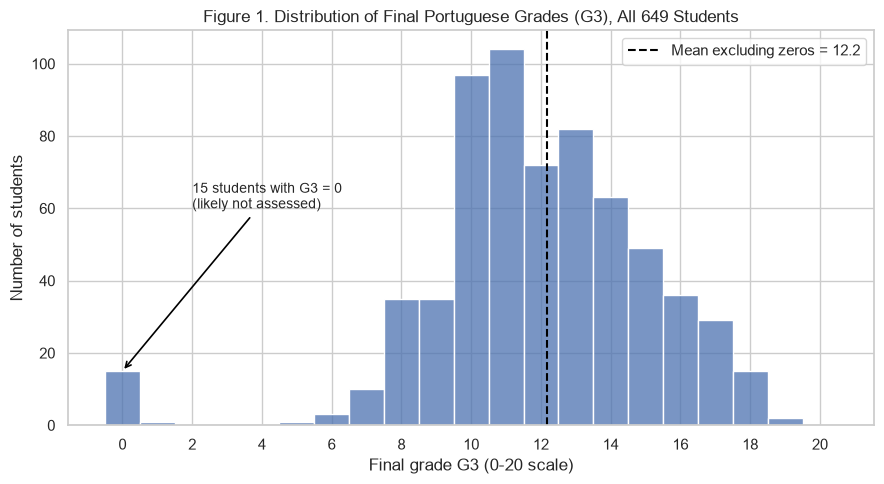

In [40]:
fig, ax = plt.subplots(figsize=(9, 5))
sns.histplot(df["G3"], bins=np.arange(-0.5, 21.5, 1), color="#4C72B0", ax=ax)
ax.axvline(analysis_df["G3"].mean(), color="black", linestyle="--",
           label=f"Mean excluding zeros = {analysis_df['G3'].mean():.1f}")
ax.annotate("15 students with G3 = 0\n(likely not assessed)", xy=(0, 15), xytext=(2, 60),
            arrowprops=dict(arrowstyle="->", color="black", lw=1.2), fontsize=10)
ax.set_title("Figure 1. Distribution of Final Portuguese Grades (G3), All 649 Students")
ax.set_xlabel("Final grade G3 (0-20 scale)")
ax.set_ylabel("Number of students")
ax.set_xticks(range(0, 21, 2))
ax.legend()
fig.tight_layout()
fig.savefig(FIG_DIR / "fig1_g3_histogram.png", dpi=200)
plt.show()

### Figure 2: Boxplot of final grades by weekly study time

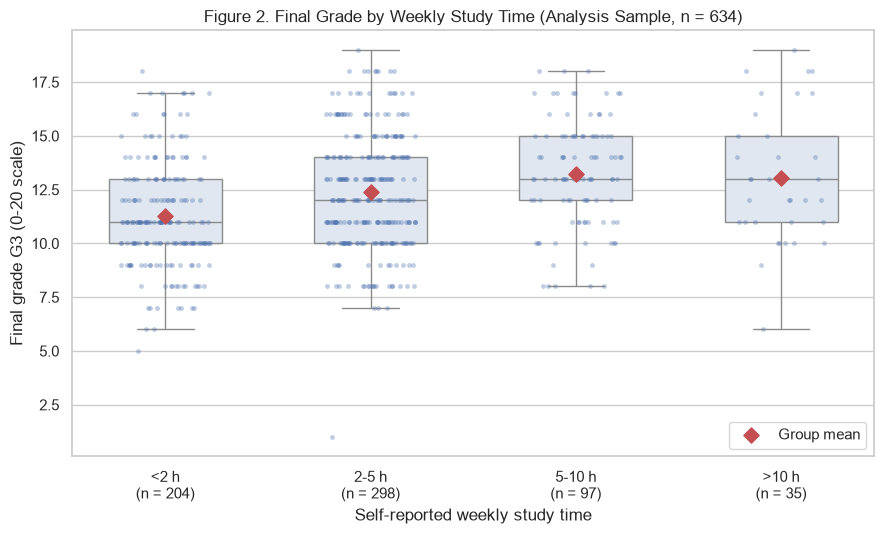

In [41]:
fig, ax = plt.subplots(figsize=(9, 5.5))
sns.boxplot(data=analysis_df, x="study_group", y="G3", color="#DDE6F3",
            showfliers=False, width=0.55, ax=ax)
# Overlay every student so the group sizes and spread stay visible
sns.stripplot(data=analysis_df, x="study_group", y="G3", color="#4C72B0",
              alpha=0.35, jitter=0.22, size=3.5, ax=ax)
group_means = analysis_df.groupby("study_group", observed=True)["G3"].mean()
ax.scatter(range(len(group_means)), group_means.values, color="#C44E52", marker="D",
           s=60, zorder=5, label="Group mean")
counts = analysis_df["study_group"].value_counts().reindex(STUDY_LABELS.values())
ax.set_xticks(range(len(counts)))
ax.set_xticklabels([f"{label}\n(n = {n})" for label, n in counts.items()])
ax.set_title("Figure 2. Final Grade by Weekly Study Time (Analysis Sample, n = 634)")
ax.set_xlabel("Self-reported weekly study time")
ax.set_ylabel("Final grade G3 (0-20 scale)")
ax.legend(loc="lower right")
fig.tight_layout()
fig.savefig(FIG_DIR / "fig2_g3_by_studytime_boxplot.png", dpi=200)
plt.show()

### Figure 3: Mean grade across the three grading periods, by study time

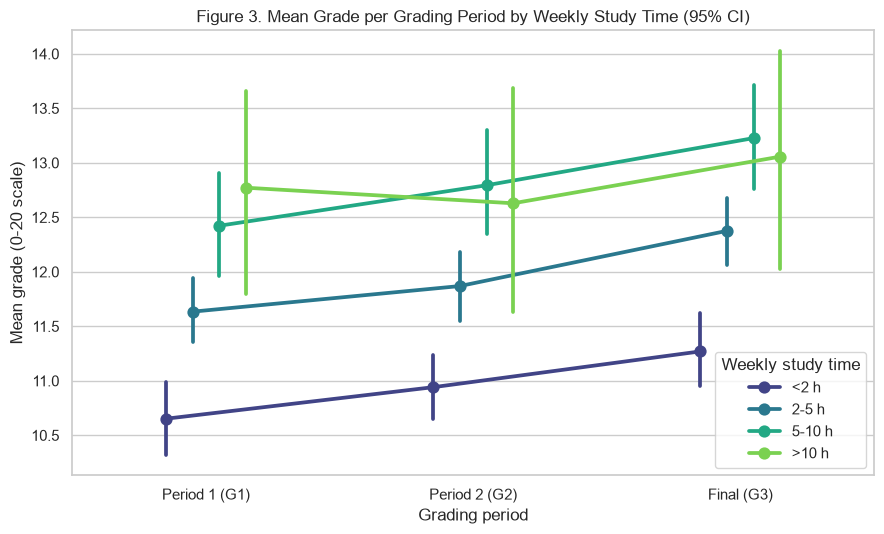

In [42]:
# Reshape to long format: one row per student per grading period
long_grades = analysis_df.melt(
    id_vars="study_group", value_vars=grades, var_name="period", value_name="grade"
)
long_grades["period"] = long_grades["period"].map(
    {"G1": "Period 1 (G1)", "G2": "Period 2 (G2)", "G3": "Final (G3)"}
)
fig, ax = plt.subplots(figsize=(9, 5.5))
sns.pointplot(data=long_grades, x="period", y="grade", hue="study_group",
              errorbar=("ci", 95), dodge=0.3, palette="viridis", ax=ax)
ax.set_title("Figure 3. Mean Grade per Grading Period by Weekly Study Time (95% CI)")
ax.set_xlabel("Grading period")
ax.set_ylabel("Mean grade (0-20 scale)")
ax.legend(title="Weekly study time", loc="lower right")
fig.tight_layout()
fig.savefig(FIG_DIR / "fig3_grade_trajectories.png", dpi=200)
plt.show()

### Figure 4: Correlation heatmap of numeric variables

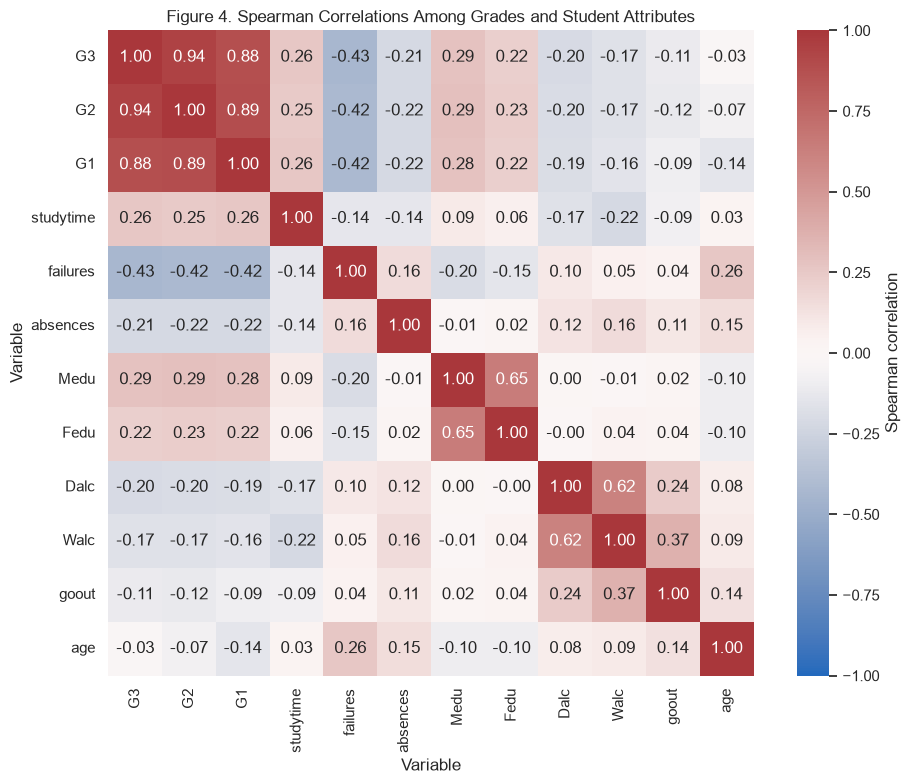

In [43]:
heat_cols = ["G3", "G2", "G1", "studytime", "failures", "absences",
             "Medu", "Fedu", "Dalc", "Walc", "goout", "age"]
corr = analysis_df[heat_cols].corr(method="spearman")
fig, ax = plt.subplots(figsize=(10, 8))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="vlag", vmin=-1, vmax=1,
            square=True, cbar_kws={"label": "Spearman correlation"}, ax=ax)
ax.set_title("Figure 4. Spearman Correlations Among Grades and Student Attributes")
ax.set_xlabel("Variable")
ax.set_ylabel("Variable")
fig.tight_layout()
fig.savefig(FIG_DIR / "fig4_correlation_heatmap.png", dpi=200)
plt.show()

### Comparing the visual models

- **Figure 1 (histogram)** shows the shape of the outcome. Final grades cluster between 10 and 14, with a roughly symmetric bell shape, plus a separate spike at 0. The spike is what flagged the 15 likely non-assessed students. It is the best figure for data quality, but it says nothing about study time.
- **Figure 2 (boxplot with every student overlaid)** compares the full distribution of final grades across the four study-time groups. The medians and means step upward from "<2 h" to "5-10 h" and then level off. The boxes overlap heavily, so study time separates the groups only modestly. Showing every point also makes the small ">10 h" group (n = 35) visible, which a bar chart of means would hide (Weissgerber et al., 2015).
- **Figure 3 (point plot over time)** adds the longitudinal view. All four groups improve slightly from period 1 to the final grade. The "<2 h" group is lowest in every period, and the gap between it and the top groups is about 2 points at G1 and still about 2 points at G3. The study-time difference is therefore present from the first period and does not grow or shrink during the year. The wide confidence intervals for ">10 h" reflect its small size.
- **Figure 4 (heatmap)** places study time among the other variables. G1, G2, and G3 are very strongly correlated with each other (0.88 to 0.94), while study time has only a weak positive correlation with G3 (0.26). Past failures (-0.43) relate more strongly to the final grade than study time does, and mother's education (0.29) about as strongly.

**Which visual model best supports the analytical question?** Figure 2. The question compares final grades across study-time groups, and the boxplot shows the group centres, the spread, the overlap, and the group sizes in one view. These are the same features the hypothesis test in Section 6 evaluates. Figures 3 and 4 add useful context: the study-time pattern is stable over time, and it is weaker than the link with past failures.

## 6. Hypothesis Test

**Test chosen:** Welch's one-way ANOVA (Welch's *F*-test), comparing mean final grade (G3) across the four weekly study-time groups.

- **Null hypothesis (H₀):** The population mean final grade is the same in all four study-time groups: μ₁ = μ₂ = μ₃ = μ₄.
- **Alternative hypothesis (H₁):** At least one study-time group has a population mean final grade that differs from the others.
- **Significance level:** α = 0.05, set before running the test.

Welch's version is used instead of the classical ANOVA *F*-test because the groups are very unequal in size (35 to 298 students) and their variances may differ. When unequal group sizes are combined with unequal variances, the classical test can give misleading *p*-values, while Welch's test loses very little when variances happen to be equal (Delacre et al., 2019). The classical *F*-test and the rank-based Kruskal-Wallis test are also reported as robustness checks.

### 6.1 Assumption checks

In [44]:
# Final grades split into one array per study-time group (ordered <2 h ... >10 h)
groups = [g["G3"].to_numpy() for _, g in analysis_df.groupby("study_group", observed=True)]
group_names = list(STUDY_LABELS.values())

# (a) Equal variances: Levene's test (median-centred, robust to non-normality)
lev_stat, lev_p = stats.levene(*groups, center="median")
print(f"Levene's test: W = {lev_stat:.3f}, p = {lev_p:.4f}")
var_ratio = max(g.var(ddof=1) for g in groups) / min(g.var(ddof=1) for g in groups)
print(f"Largest / smallest group variance ratio: {var_ratio:.2f}")

# (b) Approximate normality within each group: Shapiro-Wilk plus skewness
for name, g in zip(group_names, groups):
    sw_stat, sw_p = stats.shapiro(g)
    print(f"{name:>7}: n = {len(g):3d}, skew = {stats.skew(g):5.2f}, "
          f"Shapiro-Wilk W = {sw_stat:.3f}, p = {sw_p:.4f}")

Levene's test: W = 2.235, p = 0.0830
Largest / smallest group variance ratio: 1.55
   <2 h: n = 204, skew =  0.38, Shapiro-Wilk W = 0.969, p = 0.0002
  2-5 h: n = 298, skew = -0.01, Shapiro-Wilk W = 0.972, p = 0.0000
 5-10 h: n =  97, skew = -0.19, Shapiro-Wilk W = 0.970, p = 0.0249
  >10 h: n =  35, skew =  0.20, Shapiro-Wilk W = 0.955, p = 0.1659


**Reading the assumption checks.** Levene's test does not reject equal variances at α = 0.05 (p = 0.083), but the largest group variance is still about 1.5 times the smallest, and the smallest group (">10 h", n = 35) has the largest variance. Levene's test has limited power to detect such differences, so Welch's test, which does not assume equal variances, remains the safer choice. Shapiro-Wilk rejects exact normality in three of the four groups. This is expected, because grades are whole numbers on a bounded 0-20 scale, and with hundreds of observations the test detects even small departures. The skewness values are all small (-0.19 to 0.38), so the distributions are roughly symmetric. With group sizes of 35 or more, the mean comparison is reasonably robust to this mild non-normality. The Kruskal-Wallis test below does not assume normality at all. The remaining assumption, independent observations, comes from the study design: each student appears once. However, students in the same school may share teachers, which is discussed in the report's limitations.

### 6.2 Welch's one-way ANOVA (primary test)

In [45]:
def welch_anova(*samples):
    """Welch's heteroscedastic one-way ANOVA (Welch, 1951).

    Returns the F statistic, numerator and denominator degrees of freedom,
    and p-value. It does not assume equal group variances.
    """
    k = len(samples)
    n = np.array([len(s) for s in samples], dtype=float)
    means = np.array([np.mean(s) for s in samples])
    variances = np.array([np.var(s, ddof=1) for s in samples])
    w = n / variances                                 # precision weights
    weighted_mean = np.sum(w * means) / np.sum(w)
    numerator = np.sum(w * (means - weighted_mean) ** 2) / (k - 1)
    lam = np.sum((1 - w / np.sum(w)) ** 2 / (n - 1))
    denominator = 1 + 2 * (k - 2) / (k ** 2 - 1) * lam
    f_stat = numerator / denominator
    df1, df2 = k - 1, (k ** 2 - 1) / (3 * lam)
    p_value = stats.f.sf(f_stat, df1, df2)
    return f_stat, df1, df2, p_value


def eta_squared(*samples):
    """Proportion of total variance in the outcome explained by group membership."""
    all_values = np.concatenate(samples)
    grand_mean = all_values.mean()
    ss_between = sum(len(s) * (np.mean(s) - grand_mean) ** 2 for s in samples)
    ss_total = np.sum((all_values - grand_mean) ** 2)
    return ss_between / ss_total


f_w, df1_w, df2_w, p_w = welch_anova(*groups)
eta2 = eta_squared(*groups)
print(f"Welch's F({df1_w:.0f}, {df2_w:.1f}) = {f_w:.3f}, p = {p_w:.2e}")
print(f"Effect size: eta-squared = {eta2:.3f}")
print("Decision:", "reject H0" if p_w < ALPHA else "fail to reject H0", f"at alpha = {ALPHA}")

Welch's F(3, 133.4) = 16.418, p = 3.87e-09
Effect size: eta-squared = 0.068
Decision: reject H0 at alpha = 0.05


### 6.3 Robustness and sensitivity checks

In [46]:
# Classical one-way ANOVA (assumes equal variances) and Kruskal-Wallis (rank-based)
f_c, p_c = stats.f_oneway(*groups)
h_kw, p_kw = stats.kruskal(*groups)

# Sensitivity: rerun Welch's test with all 649 students, including G3 = 0
groups_all = [g["G3"].to_numpy() for _, g in df.groupby("studytime")]
f_all, df1_all, df2_all, p_all = welch_anova(*groups_all)

checks = pd.DataFrame(
    [
        ["Welch ANOVA (primary)", 634, f"F({df1_w:.0f}, {df2_w:.1f}) = {f_w:.2f}", p_w],
        ["Classical ANOVA", 634, f"F(3, {len(analysis_df) - 4}) = {f_c:.2f}", p_c],
        ["Kruskal-Wallis", 634, f"H(3) = {h_kw:.2f}", p_kw],
        ["Welch ANOVA, zeros kept", 649, f"F({df1_all:.0f}, {df2_all:.1f}) = {f_all:.2f}", p_all],
    ],
    columns=["Test", "n", "Test statistic", "p-value"],
)
checks["p-value"] = checks["p-value"].map(lambda p: f"{p:.2e}")
checks

,Test,n,Test statistic,p-value
0,Welch ANOVA (primary),634,"F(3, 133.4) = 16.42",3.87e-09
1,Classical ANOVA,634,"F(3, 630) = 15.42",1.09e-09
2,Kruskal-Wallis,634,H(3) = 45.58,6.98e-10
3,"Welch ANOVA, zeros kept",649,"F(3, 139.1) = 18.18",5.19e-10


### 6.4 Follow-up: which groups differ?

The omnibus test only says that *some* group differs. Pairwise Welch *t*-tests with a Holm correction for six comparisons show which pairs differ. Cohen's *d* is reported as a standardised effect size (Lakens, 2013).

In [47]:
from itertools import combinations


def holm_adjust(p_values):
    """Holm step-down adjustment for a list of p-values (controls family-wise error)."""
    p = np.asarray(p_values)
    order = np.argsort(p)
    adjusted = np.empty_like(p)
    running_max = 0.0
    for rank, idx in enumerate(order):
        running_max = max(running_max, (len(p) - rank) * p[idx])
        adjusted[idx] = min(running_max, 1.0)
    return adjusted


rows = []
for (i, a), (j, b) in combinations(enumerate(groups), 2):
    t_stat, p_raw = stats.ttest_ind(b, a, equal_var=False)   # Welch's t-test
    pooled_sd = np.sqrt((a.var(ddof=1) + b.var(ddof=1)) / 2)
    rows.append([f"{group_names[j]} vs {group_names[i]}", b.mean() - a.mean(),
                 (b.mean() - a.mean()) / pooled_sd, t_stat, p_raw])

pairwise = pd.DataFrame(rows, columns=["Comparison", "Mean difference",
                                       "Cohen's d", "Welch t", "p (raw)"])
pairwise["p (Holm)"] = holm_adjust(pairwise["p (raw)"])
pairwise["Significant at 0.05"] = pairwise["p (Holm)"] < ALPHA
pairwise.round(4)

,Comparison,Mean difference,Cohen's d,Welch t,p (raw),p (Holm),Significant at 0.05
0,2-5 h vs <2 h,1.1062,0.4308,4.7842,0.0000,0.0000,True
1,5-10 h vs <2 h,1.9572,0.7921,6.3933,0.0000,0.0000,True
2,>10 h vs <2 h,1.7875,0.6488,3.3026,0.0020,0.0079,True
3,5-10 h vs 2-5 h,0.8510,0.3275,2.8551,0.0048,0.0145,True
4,>10 h vs 2-5 h,0.6813,0.2374,1.2694,0.2115,0.4231,False
5,>10 h vs 5-10 h,-0.1697,-0.0610,-0.2961,0.7683,0.7683,False


**Result in brief** (full interpretation is in `module_summary.pdf`). Welch's test gives a very small *p*-value, so H₀ is rejected: mean final grades are not equal across the four study-time groups. Every robustness check reaches the same decision, including the analysis that keeps the 15 zero grades. The effect is modest, however. Study-time group explains only about 7% of the variation in final grades (η² = 0.068). The pairwise tests show that students who study less than 2 hours a week score lower than every other group, and the 2-5 hour group scores lower than the 5-10 hour group. The over 10 hour group does not differ significantly from either the 2-5 hour or the 5-10 hour group.

## 7. Notebook Summary

I explored whether self-reported weekly study time is related to final Portuguese grades for 649 secondary-school students. After screening, I compared 634 students across four study-time groups with Welch's ANOVA. Final grades rose from a mean of about 11.3 for students who study under 2 hours a week to about 13.2 for those who study 5 to 10 hours. This difference is statistically significant (*p* < .001) but modest, because study time explains only about 7% of the variation in grades. An unexpected finding was that the highest study-time group (over 10 hours) scored no better than the 5-10 hour group, and that past class failures relate more strongly to final grades than study time does. The main challenge was the 15 final grades of 0: their earlier grades and zero absences suggested non-assessment rather than real scores, so I set a rule to exclude them before testing and confirmed with a sensitivity analysis that the conclusion does not change.